In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Cleaned Data Load

In [3]:
# Load cleaned datasets

customers = pd.read_csv("../data/clean/customers.csv")
products = pd.read_csv("../data/clean/products.csv")
orders = pd.read_csv("../data/clean/orders.csv")

# Check dataset shapes

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)

Customers: (1200, 5)
Products: (40, 4)
Orders: (12309, 9)


Understand Orders Dataset

In [4]:
# Check column names
print("Customers Columns:")
print(customers.columns.tolist())

print("\nOrders Columns:")
print(orders.columns.tolist())

# Check data types
print("\nOrders Data Types:")
print(orders.dtypes)

Customers Columns:
['customer_id', 'city', 'signup_date', 'age', 'gender']

Orders Columns:
['order_id', 'customer_id', 'product_id', 'quantity', 'order_ts', 'status', 'discount_pct', 'order_amount', 'delivery_minutes']

Orders Data Types:
order_id                str
customer_id             str
product_id              str
quantity              int64
order_ts                str
status                  str
discount_pct          int64
order_amount        float64
delivery_minutes    float64
dtype: object


Date conversion

In [5]:
# Convert order_ts into datetime
orders["order_ts"] = pd.to_datetime(orders["order_ts"])

# Check date range
print("First Order Date:", orders["order_ts"].min())
print("Last Order Date:", orders["order_ts"].max())

# Check order status
print("\nOrder Status Counts:")
print(orders["status"].value_counts())

First Order Date: 2025-04-01 07:08:28
Last Order Date: 2025-09-30 22:46:26

Order Status Counts:
status
completed    11110
cancelled     1199
Name: count, dtype: int64


In [6]:
completed_orders = orders[
    orders["status"] == "completed"
].copy()

print("Total Completed Orders:", len(completed_orders))
print("Unique Customers:", completed_orders["customer_id"].nunique())

Total Completed Orders: 11110
Unique Customers: 1175


Create RFM Table

In [7]:
# Define snapshot date
snapshot_date = pd.Timestamp("2025-10-01 00:00:00")

# Calculate RFM metrics
rfm = completed_orders.groupby("customer_id").agg(
    last_order_ts=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum")
).reset_index()

# Calculate recency in days
rfm["recency"] = (
    snapshot_date - rfm["last_order_ts"]
).dt.days

# Keep required columns
rfm = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
]

# Display first five customers
display(rfm.head())

,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00


Verify RFM Reference Values

In [8]:
print("Total Customers:", len(rfm))

print("\nRecency:")
print(rfm["recency"].describe())

print("\nFrequency:")
print(rfm["frequency"].describe())

print("\nMonetary:")
print(rfm["monetary"].describe())

Total Customers: 1175

Recency:
count    1175.000000
mean       33.558298
std        38.433705
min         0.000000
25%         6.000000
50%        19.000000
75%        46.000000
max       180.000000
Name: recency, dtype: float64

Frequency:
count    1175.000000
mean        9.455319
std         8.009971
min         1.000000
25%         3.000000
50%         5.000000
75%        17.000000
max        33.000000
Name: frequency, dtype: float64

Monetary:
count     1175.000000
mean      2552.058553
std       2367.305104
min         12.000000
25%        505.450000
50%       2286.500000
75%       3751.525000
max      14766.550000
Name: monetary, dtype: float64


StandardScaler

In [9]:
# Select RFM features
rfm_features = rfm[
    ["recency", "frequency", "monetary"]
]

# Standardize the features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

print("Original RFM Shape:", rfm_features.shape)
print("Scaled RFM Shape:", rfm_scaled.shape)

print("\nFirst 5 Scaled Rows:")
print(rfm_scaled[:5])

Original RFM Shape: (1175, 3)
Scaled RFM Shape: (1175, 3)

First 5 Scaled Rows:
[[-0.50910069 -0.68135607 -0.86177183]
 [-0.14468198 -0.30666338  0.88443715]
 [-0.69131004  1.56680006  0.4618149 ]
 [-0.8735194  -0.5564585  -0.922563  ]
 [ 2.95287704 -0.93115119 -0.94158005]]


Find the Optimal K (K=2 to K=8)

In [10]:
from sklearn.metrics import silhouette_score

# Store results
kmeans_results = []

# Test K values from 2 to 8
for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(rfm_scaled, labels)

    kmeans_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

# Convert results into DataFrame
kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(3))

,K,Inertia,Silhouette Score
0,2,1820.761,0.465
1,3,1268.235,0.445
2,4,743.071,0.526
3,5,617.367,0.480
4,6,503.171,0.482
5,7,408.460,0.416
6,8,366.503,0.412


Train Final K-Means Model

In [11]:
# Final K-Means model
final_kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

# Assign cluster labels
rfm["segment_id"] = final_kmeans.fit_predict(rfm_scaled)

# Check segment counts
print("Customer Count per Segment:")
print(rfm["segment_id"].value_counts().sort_index())

Customer Count per Segment:
segment_id
0    436
1    138
2    419
3    182
Name: count, dtype: int64


Understand each customer segment

In [12]:
segment_profile = rfm.groupby("segment_id").agg(
    customer_count=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).round(2)

display(segment_profile)

,customer_count,avg_recency,avg_frequency,avg_monetary
segment_id,,,,
0,436,28.86,3.77,1057.62
1,138,24.12,6.77,7129.70
2,419,8.77,19.40,3410.02
3,182,109.04,2.20,685.99


Segment name assigning

In [13]:
segment_names = {
    0: "Occasional Customers",
    1: "Premium Customers",
    2: "Loyal Customers",
    3: "At-Risk Customers"
}

rfm["segment_name"] = rfm["segment_id"].map(segment_names)

rfm["is_premium"] = (
    rfm["segment_id"] == 1
)

display(rfm.head())

,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Occasional Customers,False
1,C0002,28,7,4644.90,1,Premium Customers,True
2,C0003,7,22,3644.85,2,Loyal Customers,False
3,C0004,0,5,369.00,0,Occasional Customers,False
4,C0005,147,2,324.00,3,At-Risk Customers,False


PCA visualization

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.63427875 0.21803762]

Total Explained Variance:
0.8523163667502168


PCA scatter plot

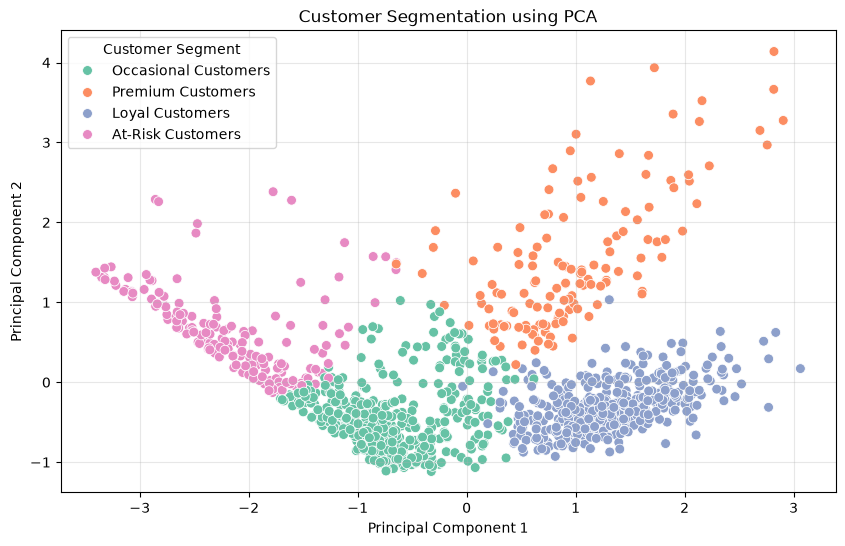

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=rfm_pca[:, 0],
    y=rfm_pca[:, 1],
    hue=rfm["segment_name"],
    palette="Set2",
    s=50
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Segment")
plt.grid(alpha=0.3)
plt.show()

Save required CSV

In [16]:
import os

os.makedirs("../outputs", exist_ok=True)

customer_segments = rfm[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "segment_id",
        "segment_name",
        "is_premium"
    ]
].copy()

customer_segments.to_csv(
    "../outputs/customer_segments.csv",
    index=False
)

print("Customer segments saved successfully!")
print("Shape:", customer_segments.shape)
print(customer_segments.head())

Customer segments saved successfully!
Shape: (1175, 7)
  customer_id  recency  frequency  monetary  segment_id          segment_name  \
0       C0001       14          4    512.85           0  Occasional Customers   
1       C0002       28          7   4644.90           1     Premium Customers   
2       C0003        7         22   3644.85           2       Loyal Customers   
3       C0004        0          5    369.00           0  Occasional Customers   
4       C0005      147          2    324.00           3     At-Risk Customers   

   is_premium  
0       False  
1        True  
2       False  
3       False  
4       False  


Lapse prediction dataset

In [17]:
cutoff_date = pd.Timestamp("2025-09-01")

# Orders before cutoff date
pre_cutoff_orders = orders[
    orders["order_ts"] < cutoff_date
].copy()

# Completed orders before cutoff
pre_cutoff_completed = pre_cutoff_orders[
    pre_cutoff_orders["status"] == "completed"
].copy()

# Completed orders during September
september_completed = orders[
    (orders["order_ts"] >= cutoff_date) &
    (orders["order_ts"] < pd.Timestamp("2025-10-01")) &
    (orders["status"] == "completed")
].copy()

print("Pre-cutoff orders:", len(pre_cutoff_orders))
print("Pre-cutoff completed orders:", len(pre_cutoff_completed))
print("September completed orders:", len(september_completed))

print(
    "Customers with pre-cutoff completed orders:",
    pre_cutoff_completed["customer_id"].nunique()
)

Pre-cutoff orders: 10301
Pre-cutoff completed orders: 9281
September completed orders: 1829
Customers with pre-cutoff completed orders: 1156


Create the Lapse Target (lapsed)

In [18]:
# Customers with at least one completed order before cutoff
cohort = pd.DataFrame({
    "customer_id": pre_cutoff_completed["customer_id"].unique()
})

# Customers who completed at least one order in September
september_customer_ids = set(
    september_completed["customer_id"].unique()
)

# Create lapse label
cohort["lapsed"] = (
    ~cohort["customer_id"].isin(september_customer_ids)
).astype(int)

# Check label distribution
print("Cohort shape:", cohort.shape)

print("\nLapse distribution:")
print(cohort["lapsed"].value_counts().sort_index())

print("\nLapse percentage:")
print(
    (cohort["lapsed"].value_counts(normalize=True) * 100).round(2)
)

Cohort shape: (1156, 2)

Lapse distribution:
lapsed
0    713
1    443
Name: count, dtype: int64

Lapse percentage:
lapsed
0    61.68
1    38.32
Name: proportion, dtype: float64


RFM + discount + delivery features

In [19]:
customer_features = pre_cutoff_completed.groupby("customer_id").agg(
    last_order_ts=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum"),
    avg_discount=("discount_pct", "mean"),
    avg_delivery_minutes=("delivery_minutes", "mean")
).reset_index()

# Recency calculated using cutoff date
customer_features["recency"] = (
    cutoff_date - customer_features["last_order_ts"]
).dt.days

# Remove helper column
customer_features.drop(columns=["last_order_ts"], inplace=True)

display(customer_features.head())
print("Shape:", customer_features.shape)

C:\Users\kamali\AppData\Local\Temp\ipykernel_20792\964282426.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  customer_features.drop(columns=["last_order_ts"], inplace=True)


,customer_id,frequency,monetary,avg_discount,avg_delivery_minutes,recency
0,C0001,2,378.00,10.000000,28.000000,33
1,C0002,6,3946.90,6.666667,21.916667,22
2,C0003,20,3264.05,12.750000,24.200000,1
3,C0004,3,272.25,11.666667,35.666667,42
4,C0005,2,324.00,25.000000,26.000000,117


Shape: (1156, 6)


Calculate cancellation rate

In [20]:
cancellation_features = pre_cutoff_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=(
        "status",
        lambda x: (x == "cancelled").sum()
    )
).reset_index()

cancellation_features["cancellation_rate"] = (
    cancellation_features["cancelled_orders"] /
    cancellation_features["total_orders"]
)

display(cancellation_features.head())

print("Shape:", cancellation_features.shape)

print(
    "Missing cancellation rates:",
    cancellation_features["cancellation_rate"].isna().sum()
)

,customer_id,total_orders,cancelled_orders,cancellation_rate
0,C0001,2,0,0.000000
1,C0002,6,0,0.000000
2,C0003,20,0,0.000000
3,C0004,5,2,0.400000
4,C0005,3,1,0.333333


Shape: (1171, 4)
Missing cancellation rates: 0


Favourite product category

In [21]:
# Add product category to completed orders
completed_with_category = pre_cutoff_completed.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

# Count orders by customer and category
category_counts = (
    completed_with_category
    .groupby(["customer_id", "category"])
    .size()
    .reset_index(name="category_orders")
)

# Select the most frequently ordered category per customer
favorite_category = (
    category_counts
    .sort_values(
        ["customer_id", "category_orders", "category"],
        ascending=[True, False, True]
    )
    .drop_duplicates("customer_id")
    [["customer_id", "category"]]
    .rename(columns={"category": "favorite_category"})
)

display(favorite_category.head())

print("Shape:", favorite_category.shape)
print(
    "Missing favorite categories:",
    favorite_category["favorite_category"].isna().sum()
)

,customer_id,favorite_category
0,C0001,Grocery
2,C0002,Electronics
6,C0003,Grocery
9,C0004,Snacks
10,C0005,Dairy


Shape: (1156, 2)
Missing favorite categories: 0


Add customer details and tenure

In [22]:
# Select customer details
customer_details = customers[
    ["customer_id", "city", "age", "gender", "signup_date"]
].copy()

# Convert signup_date to datetime
customer_details["signup_date"] = pd.to_datetime(
    customer_details["signup_date"]
)

# Calculate tenure in days as of cutoff date
customer_details["tenure_days"] = (
    cutoff_date - customer_details["signup_date"]
).dt.days

# Remove signup_date helper column
customer_details = customer_details.drop(
    columns=["signup_date"]
)

display(customer_details.head())

print("Shape:", customer_details.shape)
print("Missing values:")
print(customer_details.isnull().sum())

,customer_id,city,age,gender,tenure_days
0,C0001,Chennai,35.0,male,597
1,C0002,Delhi,31.0,male,562
2,C0003,Bengaluru,18.0,female,195
3,C0004,Bengaluru,24.0,female,437
4,C0005,Bengaluru,25.0,female,335


Shape: (1200, 5)
Missing values:
customer_id    0
city           0
age            0
gender         0
tenure_days    0
dtype: int64


Merge all features

In [23]:
# Start with eligible customer cohort
lapse_data = cohort.copy()

# Merge completed-order behaviour features
lapse_data = lapse_data.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Merge cancellation rate
lapse_data = lapse_data.merge(
    cancellation_features[
        ["customer_id", "cancellation_rate"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Merge favourite category
lapse_data = lapse_data.merge(
    favorite_category,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Merge customer details
lapse_data = lapse_data.merge(
    customer_details,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Final dataset shape:", lapse_data.shape)

print("\nMissing values:")
print(lapse_data.isnull().sum())

print("\nFirst five rows:")
display(lapse_data.head())

Final dataset shape: (1156, 13)

Missing values:
customer_id             0
lapsed                  0
frequency               0
monetary                0
avg_discount            0
avg_delivery_minutes    0
recency                 0
cancellation_rate       0
favorite_category       0
city                    0
age                     0
gender                  0
tenure_days             0
dtype: int64

First five rows:


,customer_id,lapsed,frequency,monetary,avg_discount,avg_delivery_minutes,recency,cancellation_rate,favorite_category,city,age,gender,tenure_days
0,C0967,1,2,185.1,27.50,24.5000,77,0.000000,Grocery,Hyderabad,46.0,male,458
1,C1117,0,4,4394.7,13.75,24.5000,29,0.000000,Electronics,Pune,54.0,female,528
2,C0569,0,4,553.4,6.25,27.7500,42,0.000000,Dairy,Bengaluru,25.0,male,498
3,C0776,0,20,4428.8,10.50,26.9500,1,0.000000,Dairy,Mumbai,39.0,male,219
4,C1122,0,16,2503.5,11.25,28.8125,5,0.111111,Dairy,Mumbai,58.0,male,580


Check data leakage and dataset quality

In [24]:
# Check duplicate customers
print(
    "Duplicate customer IDs:",
    lapse_data["customer_id"].duplicated().sum()
)

# Check missing values
print(
    "\nTotal missing values:",
    lapse_data.isnull().sum().sum()
)

# Check feature date boundaries
print(
    "\nLatest pre-cutoff feature order date:",
    pre_cutoff_completed["order_ts"].max()
)

print(
    "Cutoff date:",
    cutoff_date
)

# Check target distribution
print("\nLapse distribution:")
print(lapse_data["lapsed"].value_counts())

# Check feature columns
feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount",
    "cancellation_rate",
    "avg_delivery_minutes",
    "favorite_category",
    "city",
    "age",
    "gender",
    "tenure_days"
]

print("\nFeature count:", len(feature_columns))
print("Target column: lapsed")

Duplicate customer IDs: 0

Total missing values: 0

Latest pre-cutoff feature order date: 2025-08-31 22:35:45
Cutoff date: 2025-09-01 00:00:00

Lapse distribution:
lapsed
0    713
1    443
Name: count, dtype: int64

Feature count: 11
Target column: lapsed


Train/Test Split

In [25]:
# Define features and target
X = lapse_data[feature_columns].copy()
y = lapse_data["lapsed"].copy()

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training shape: (924, 11)
Testing shape: (232, 11)

Training target distribution:
lapsed
0    570
1    354
Name: count, dtype: int64

Testing target distribution:
lapsed
0    143
1     89
Name: count, dtype: int64


Baseline Model

In [26]:
# Baseline predicts every customer as Not Lapsed (0)
baseline_predictions = np.zeros(len(y_test), dtype=int)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    zero_division=0
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Positive-class F1:", round(baseline_f1, 4))

Baseline Accuracy: 0.6164
Baseline Positive-class F1: 0.0


Data preprocessing

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Numerical features
numeric_features = [
    "recency",
    "frequency",
    "monetary",
    "avg_discount",
    "cancellation_rate",
    "avg_delivery_minutes",
    "age",
    "tenure_days"
]

# Categorical features
categorical_features = [
    "city",
    "gender",
    "favorite_category"
]

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (924, 19)
Testing processed shape: (232, 19)


Check StandardScaler learned mean

In [28]:
# Get the StandardScaler fitted on training data
fitted_scaler = preprocessor.named_transformers_["num"]

# Find the frequency column position
frequency_index = numeric_features.index("frequency")

# Mean learned from training data
training_frequency_mean = fitted_scaler.mean_[frequency_index]

# Mean from the complete cohort
full_cohort_frequency_mean = lapse_data["frequency"].mean()

print(
    "Training frequency mean:",
    round(training_frequency_mean, 4)
)

print(
    "Full cohort frequency mean:",
    round(full_cohort_frequency_mean, 4)
)

print(
    "Difference:",
    round(
        training_frequency_mean - full_cohort_frequency_mean,
        4
    )
)

Training frequency mean: 8.1158
Full cohort frequency mean: 8.0285
Difference: 0.0873


Logistic Regression with GridSearchCV

In [29]:
from sklearn.model_selection import GridSearchCV

# Create Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Hyperparameter values to test
logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Grid Search with 5-fold cross-validation
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and tune
logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(logistic_grid.best_score_, 4))

Best Logistic Regression Parameters:
{'model__C': 0.1}

Best Cross-Validation F1:
0.6392


Random Forest tuning

In [30]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_param_grid = {
    "model__max_depth": [3, 5, 8],
    "model__min_samples_leaf": [5, 10, 20]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'model__max_depth': 3, 'model__min_samples_leaf': 5}

Best Cross-Validation F1:
0.6748


Test both models

In [31]:
# Get best tuned models
best_logistic_model = logistic_grid.best_estimator_
best_rf_model = rf_grid.best_estimator_

# Predict on untouched test data
logistic_predictions = best_logistic_model.predict(X_test)
rf_predictions = best_rf_model.predict(X_test)

# Function to evaluate models
def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 40)

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("Precision:", round(
        precision_score(y_true, y_pred, zero_division=0), 4
    ))

    print("Recall:", round(
        recall_score(y_true, y_pred, zero_division=0), 4
    ))

    print("F1 Score:", round(
        f1_score(y_true, y_pred, zero_division=0), 4
    ))

# Evaluate both
evaluate_model("Logistic Regression", y_test, logistic_predictions)
evaluate_model("Random Forest", y_test, rf_predictions)


Logistic Regression
----------------------------------------
Confusion Matrix:
[[105  38]
 [ 17  72]]
Precision: 0.6545
Recall: 0.809
F1 Score: 0.7236

Random Forest
----------------------------------------
Confusion Matrix:
[[112  31]
 [ 23  66]]
Precision: 0.6804
Recall: 0.7416
F1 Score: 0.7097


Logistic Regression was selected because it achieved a higher test F1 score of 0.7236 compared with Random Forest's 0.7097. It also achieved higher recall (0.8090), identifying more customers who actually lapsed. However, its lower precision means it incorrectly targets more loyal customers, resulting in 38 false positives compared with Random Forest's 31. For a retention campaign, identifying more potentially lapsed customers is valuable, provided the business can manage the additional outreach cost.

Oversampling

In [32]:
from sklearn.utils import resample, shuffle
from sklearn.base import clone

# Separate lapsed and loyal training customers
X_lapsed = X_train[y_train == 1]
y_lapsed = y_train[y_train == 1]

# Duplicate lapsed customers with replacement
X_lapsed_oversampled, y_lapsed_oversampled = resample(
    X_lapsed,
    y_lapsed,
    replace=True,
    n_samples=570,
    random_state=42
)

# Keep all original training rows and add duplicated lapsed rows
X_train_balanced = pd.concat([
    X_train,
    X_lapsed_oversampled
])

y_train_balanced = pd.concat([
    y_train,
    y_lapsed_oversampled
])

# Shuffle the balanced training dataset
X_train_balanced, y_train_balanced = shuffle(
    X_train_balanced,
    y_train_balanced,
    random_state=42
)

print("Balanced training distribution:")
print(y_train_balanced.value_counts().sort_index())

print("\nBalanced training shape:", X_train_balanced.shape)

Balanced training distribution:
lapsed
0    570
1    924
Name: count, dtype: int64

Balanced training shape: (1494, 11)


Correct the oversampling

In [33]:
from sklearn.utils import resample, shuffle

# Select only lapsed customers from original training data
X_lapsed = X_train[y_train == 1]
y_lapsed = y_train[y_train == 1]

# Calculate how many extra rows are needed
additional_rows = 570 - len(X_lapsed)

# Duplicate only the required number of lapsed rows
X_lapsed_oversampled, y_lapsed_oversampled = resample(
    X_lapsed,
    y_lapsed,
    replace=True,
    n_samples=additional_rows,
    random_state=42
)

# Combine original training data with duplicated rows
X_train_balanced = pd.concat([
    X_train,
    X_lapsed_oversampled
])

y_train_balanced = pd.concat([
    y_train,
    y_lapsed_oversampled
])

# Shuffle the balanced data
X_train_balanced, y_train_balanced = shuffle(
    X_train_balanced,
    y_train_balanced,
    random_state=42
)

print("Balanced training distribution:")
print(y_train_balanced.value_counts().sort_index())

print("\nBalanced training shape:", X_train_balanced.shape)

Balanced training distribution:
lapsed
0    570
1    570
Name: count, dtype: int64

Balanced training shape: (1140, 11)


Retrain Logistic Regression

In [34]:
# Create a fresh copy of the best Logistic Regression pipeline
balanced_logistic_model = clone(best_logistic_model)

# Train using balanced training data
balanced_logistic_model.fit(
    X_train_balanced,
    y_train_balanced
)

# Predict on the original, unchanged test data
balanced_predictions = balanced_logistic_model.predict(X_test)

# Evaluate performance
evaluate_model(
    "Logistic Regression - After Oversampling",
    y_test,
    balanced_predictions
)


Logistic Regression - After Oversampling
----------------------------------------
Confusion Matrix:
[[86 57]
 [ 8 81]]
Precision: 0.587
Recall: 0.9101
F1 Score: 0.7137


After oversampling, recall increased from 0.8090 to 0.9101, while precision decreased from 0.6545 to 0.5870. Recall showed the largest absolute improvement, increasing by 0.1011. This indicates that the model identifies more genuinely lapsed customers but also targets more loyal customers unnecessarily. The business must balance improved customer recovery opportunities against the additional retention campaign cost.

Feature Importance

In [35]:
# Get the trained Random Forest pipeline
best_rf_model = rf_grid.best_estimator_

# Extract feature importance
rf_importances = best_rf_model.named_steps["model"].feature_importances_

# Get feature names after preprocessing
feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
})

# Sort and display top 5
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.head(5).round(4))

,Feature,Importance
1,num__frequency,0.3522
2,num__monetary,0.2887
0,num__recency,0.1150
4,num__cancellation_rate,0.0531
3,num__avg_discount,0.0407


Frequency (35.22%): Customers who order less frequently may need engagement campaigns.

Monetary (28.87%): Customer spending behaviour is an important indicator for retention planning.

Recency (11.50%): Customers who have not ordered recently may need re-engagement offers.

Cancellation rate (5.31%): Frequent cancellations may indicate customer experience issues.

Average discount (4.07%): Discount usage contributes to the model's predictions.

Logistic Regression coefficient signs

In [36]:
# Get the best Logistic Regression model
best_logistic_model = logistic_grid.best_estimator_

# Extract model coefficients
logistic_coefficients = best_logistic_model.named_steps[
    "model"
].coef_[0]

# Get feature names after preprocessing
feature_names = best_logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create coefficient table
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_coefficients
})

# Sort by absolute coefficient value
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coefficient_df.head(3).round(4))

,Feature,Coefficient,Absolute_Coefficient
1,num__frequency,-1.2811,1.2811
15,cat__favorite_category_Electronics,-0.3782,0.3782
18,cat__favorite_category_Snacks,-0.2026,0.2026


Frequency has the strongest negative coefficient among the three features, indicating that customers who order more frequently tend to have a lower predicted likelihood of lapsing. Electronics and Snacks also have negative coefficients compared with the reference category, Dairy. These are model associations, not proof that purchasing a particular category prevents customers from lapsing.

Save the selected model

In [37]:
import joblib
import os
import numpy as np

# Select original Logistic Regression model
selected_model = best_logistic_model

# Create output folder if needed
os.makedirs("../outputs", exist_ok=True)

# Save model
model_path = "../outputs/lapse_model.joblib"
joblib.dump(selected_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)

# Reload saved model
loaded_model = joblib.load(model_path)

# Predict using original and reloaded models
original_predictions = selected_model.predict(X_test)
reloaded_predictions = loaded_model.predict(X_test)

# Verify predictions are identical
assert np.array_equal(
    original_predictions,
    reloaded_predictions
)

print("\nModel reload verification: PASSED")
print("All test predictions are identical.")

Model saved successfully!
Path: ../outputs/lapse_model.joblib

Model reload verification: PASSED
All test predictions are identical.


Create Premium customer retention list

In [38]:
# Get customer IDs belonging to the test dataset
test_customer_ids = lapse_data.loc[
    X_test.index, ["customer_id", "lapsed"]
].copy()

# Preserve original test row index
test_customer_ids["_row_index"] = X_test.index

# Add Premium segment information
premium_test = test_customer_ids.merge(
    customer_segments[["customer_id", "is_premium"]],
    on="customer_id",
    how="left"
)

# Keep only Premium customers
premium_test = premium_test[
    premium_test["is_premium"] == True
].copy()

# Get the correct original test rows
premium_X_test = X_test.loc[
    premium_test["_row_index"].tolist()
]

# Predict lapse probabilities
premium_test["lapse_probability"] = loaded_model.predict_proba(
    premium_X_test
)[:, 1]

# Rename actual target column
premium_test = premium_test.rename(
    columns={"lapsed": "actually_lapsed"}
)

# Sort and select Top 10
retention_list = premium_test.sort_values(
    by="lapse_probability",
    ascending=False
).head(10)

# Keep required columns
retention_list = retention_list[
    ["customer_id", "lapse_probability", "actually_lapsed"]
].copy()

# Save CSV
retention_list.to_csv(
    "../outputs/retention_list.csv",
    index=False
)

display(retention_list.round(4))

print("\nRetention list saved successfully!")
print("Number of Premium customers selected:", len(retention_list))
print(
    "Actually lapsed customers in this list:",
    retention_list["actually_lapsed"].sum()
)


,customer_id,lapse_probability,actually_lapsed
106,C0577,0.5750,0
19,C0102,0.5704,1
136,C0697,0.5475,0
28,C0942,0.5099,0
139,C0831,0.4959,0
181,C0509,0.4765,0
216,C0162,0.4764,0
196,C0324,0.4763,0
74,C0977,0.4449,1
60,C0299,0.4447,0



Retention list saved successfully!
Number of Premium customers selected: 10
Actually lapsed customers in this list: 2


In [39]:
# Get test customer details and preserve original index
test_customer_ids = lapse_data.loc[
    X_test.index, ["customer_id", "lapsed"]
].copy()

test_customer_ids["_row_index"] = X_test.index

# Merge Premium information
premium_test = test_customer_ids.merge(
    customer_segments[["customer_id", "is_premium"]],
    on="customer_id",
    how="left"
)

# Select Premium customers
premium_test = premium_test[
    premium_test["is_premium"] == True
].copy()

# Retrieve correct test rows using preserved index
premium_X_test = X_test.loc[
    premium_test["_row_index"].tolist()
]

# Predict lapse probability
premium_test["lapse_probability"] = (
    loaded_model.predict_proba(premium_X_test)[:, 1]
)

# Sort and select top 10
retention_list = premium_test.sort_values(
    "lapse_probability",
    ascending=False
).head(10)[
    ["customer_id", "lapse_probability", "lapsed"]
].rename(columns={"lapsed": "actually_lapsed"})

# Save output
retention_list.to_csv(
    "../outputs/retention_list.csv",
    index=False
)

display(retention_list.round(4))

print("Retention list saved successfully!")
print("Selected customers:", len(retention_list))
print(
    "Actually lapsed customers:",
    retention_list["actually_lapsed"].sum()
)

,customer_id,lapse_probability,actually_lapsed
106,C0577,0.5750,0
19,C0102,0.5704,1
136,C0697,0.5475,0
28,C0942,0.5099,0
139,C0831,0.4959,0
181,C0509,0.4765,0
216,C0162,0.4764,0
196,C0324,0.4763,0
74,C0977,0.4449,1
60,C0299,0.4447,0


Retention list saved successfully!
Selected customers: 10
Actually lapsed customers: 2


In [40]:
import os
import pandas as pd

required_files = [
    "../outputs/customer_segments.csv",
    "../outputs/lapse_model.joblib",
    "../outputs/retention_list.csv"
]

for file in required_files:
    print(
        os.path.basename(file),
        "EXISTS" if os.path.exists(file) else "MISSING"
    )

# Verify CSV structures
segments_check = pd.read_csv("../outputs/customer_segments.csv")
retention_check = pd.read_csv("../outputs/retention_list.csv")

print("\nCustomer segments shape:", segments_check.shape)
print("Retention list shape:", retention_check.shape)

print("\nRetention columns:")
print(retention_check.columns.tolist())

customer_segments.csv EXISTS
lapse_model.joblib EXISTS
retention_list.csv EXISTS

Customer segments shape: (1175, 7)
Retention list shape: (10, 3)

Retention columns:
['customer_id', 'lapse_probability', 'actually_lapsed']


In [41]:
import joblib

# Load the saved ML model
model = joblib.load("../outputs/lapse_model.joblib")

print("Model loaded successfully!")
print(model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['recency', 'frequency',
                                                   'monetary', 'avg_discount',
                                                   'cancellation_rate',
                                                   'avg_delivery_minutes',
                                                   'age', 'tenure_days']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['city', 'gender',
                                                   'favorite_category'])])),
                ('model', LogisticRegression(C=0.1, max_iter=1000))])


In [42]:
# Predict using test dataset
predictions = model.predict(X_test)

# Display first 10 predictions
print(predictions[:10])

[1 1 0 1 1 0 0 1 0 0]


In [43]:
probabilities = model.predict_proba(X_test)

results = pd.DataFrame({
    "customer_id": lapse_data.loc[X_test.index, "customer_id"].values,
    "actual_status": y_test.values,
    "predicted_status": predictions,
    "lapse_probability": probabilities[:, 1]
})

display(results.head(10).round(4))

,customer_id,actual_status,predicted_status,lapse_probability
0,C1196,1,1,0.6269
1,C0393,1,1,0.5740
2,C0850,0,0,0.4506
3,C0676,0,1,0.6174
4,C0722,0,1,0.5606
5,C0854,0,0,0.1116
6,C0004,0,0,0.4942
7,C0184,1,1,0.5232
8,C0400,0,0,0.0738
9,C0804,0,0,0.1260


In [44]:
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

print("No missing values in train/test features.")

No missing values in train/test features.


In [45]:
y_pred = best_logistic_model.predict(X_test)

In [46]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[105  38]
 [ 17  72]]
Accuracy: 0.7629310344827587
Precision: 0.6545454545454545
Recall: 0.8089887640449438
F1 Score: 0.7236180904522613


### Why Lower Inertia Alone Cannot Determine the Best K

As the number of clusters (K) increases, K-Means inertia generally decreases because customers are divided into smaller, more compact groups. Therefore, K=8 naturally has lower inertia than K=2. However, lower inertia alone does not indicate the best clustering solution, because increasing K can create too many small or less meaningful segments. K=4 was selected because it provides a good balance between the elbow point, the highest silhouette score (0.526), and business interpretability.

### Model Limitations and Next Steps

**Limitations:**

1. **Limited historical data:** The model uses customer activity from a limited historical period. Customer behaviour may change over time, so the model may not perform equally well on future data.
2. **Feature importance does not prove causation:** Random Forest feature importance and Logistic Regression coefficients show associations with predicted customer lapse. They do not prove that a particular feature directly causes or prevents customer churn.
3. **Post-hoc Premium identification:** The Premium flag is based on the whole-window RFM segmentation, including the September period used to define the lapse label. Therefore, the retention list is illustrative and not a leakage-free prospective evaluation. The model's own features still use only orders before the 2025-09-01 cutoff.
4. **Class imbalance:** Oversampling improved recall but reduced precision, meaning more loyal customers may be incorrectly targeted by retention campaigns.

**Next Steps:**

1. Validate the model using newer customer data and a separate future time period.
2. Monitor precision, recall and F1 regularly to identify changes in model performance.
3. Test different classification thresholds based on the business cost of missed lapsing customers and unnecessary retention offers.
4. Conduct A/B testing of retention campaigns to measure whether targeted offers actually improve customer retention.
5. Collect more customer behaviour and feedback data to improve future predictions.

In [47]:
import pandas as pd

segments = pd.read_csv(
    r"C:\Users\kamali\OneDrive\Documents\captone\outputs\customer_segments.csv"
)

print(segments.columns.tolist())
display(segments.head())

['customer_id', 'recency', 'frequency', 'monetary', 'segment_id', 'segment_name', 'is_premium']


,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Occasional Customers,False
1,C0002,28,7,4644.90,1,Premium Customers,True
2,C0003,7,22,3644.85,2,Loyal Customers,False
3,C0004,0,5,369.00,0,Occasional Customers,False
4,C0005,147,2,324.00,3,At-Risk Customers,False


In [48]:
segment_summary = (
    segments.groupby("segment_name")[["recency", "frequency", "monetary"]]
    .mean()
    .round(2)
)

display(segment_summary)

,recency,frequency,monetary
segment_name,,,
At-Risk Customers,109.04,2.20,685.99
Loyal Customers,8.77,19.40,3410.02
Occasional Customers,28.86,3.77,1057.62
Premium Customers,24.12,6.77,7129.70


In [ ]:
print("Logistic Regression")
print("Confusion Matrix:")
print(cm_lr)
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1:", f1_lr)

print("\nRandom Forest")
print("Confusion Matrix:")
print(cm_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1:", f1_rf)

Logistic Regression
Confusion Matrix:


NameError: name 'precision_lr' is not defined

In [ ]:
print([name for name in globals() if "lr" in name.lower() or "logistic" in name.lower()])

['LogisticRegression', 'logistic_pipeline', 'logistic_param_grid', 'logistic_grid', 'best_logistic_model', 'logistic_predictions', 'balanced_logistic_model', 'logistic_coefficients']


In [ ]:
print(rfm.columns.tolist())

['customer_id', 'recency', 'frequency', 'monetary', 'segment_id', 'segment_name', 'is_premium']
